<H2> <font color="crimson";>EXPLORATORY DATA ANALYSIS(EDA) ON SUPERSTORE RETAIL SALES</H2>

In [1]:
#Importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-ready chart styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120



In [2]:
# Loading the  dataset
df = pd.read_csv("/content/sample_data/superstore_sales.csv")

In [3]:
# Preview the first 5 rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


<h3> <font color="crimson">Data Inspection</h3>

In [4]:
# Check dataset dimensions, column types, and missing values
print(f"Dataset Shape: {df.shape}\n")
print("--- Data Info ---")
df.info()

Dataset Shape: (10800, 21)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sale

In [5]:
print("\n--- Missing Values ---")
print(df.isnull().sum())


--- Missing Values ---
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [6]:
print("\n--- Duplicate Rows ---")
print(f"Duplicates: {df.duplicated().sum()}")


--- Duplicate Rows ---
Duplicates: 504


In [7]:
# Drop exact duplicate rows if any exist
df.drop_duplicates(inplace=True)

In [8]:
# Droping those non-order metadata rows and reset the DataFrame index.
df.dropna(subset=["Order Date", "Sales"], inplace=True)
df.reset_index(drop=True, inplace=True)

In [9]:
# Inspecting remaining missing values after isolating valid order records
print("\n--- Remaining Missing Values (Valid Orders) ---")
print(df.isnull().sum()[df.isnull().sum() > 0])


--- Remaining Missing Values (Valid Orders) ---
Postal Code    11
dtype: int64


In [10]:
# Impute the 11 missing Postal Codes for Burlington, Vermont (standard ZIP: 05401)
df["Postal Code"] = df["Postal Code"].fillna(5401)

In [11]:
# Enforce clean, consistent data types across ID, numeric, and string columns
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

In [12]:
# Confirm final cleaned dimensions and zero remaining missing values
print(f"\nCleaned Dataset Shape: {df.shape}")
print(f"Total Remaining Nulls: {df.isnull().sum().sum()}")


Cleaned Dataset Shape: (9994, 21)
Total Remaining Nulls: 0


In [14]:
# Preview the first 5 rows again
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<h3> <font color="crimson">Data Cleaning & Feature Engineering<?h3>

In [15]:
# Convert Order Date and Ship Date from text strings into datetime64 objects
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")


In [16]:

# Extract calendar attributes for seasonality and time-series analysis
df["Order_Year"] = df["Order Date"].dt.year                         # Calendar year (2015–2018)
df["Order_Month"] = df["Order Date"].dt.month                       # Numeric month (1–12)
df["Month_Name"] = df["Order Date"].dt.strftime("%b")               # Abbreviated month name (Jan–Dec)
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)   # YYYY-MM period string for trend plots


In [17]:

# Engineer fulfillment and financial performance metrics
df["Shipping_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days  # Order-to-ship lead time in days
df["Profit_Margin_Pct"] = np.where(                                 # Line-item profit margin percentage
    df["Sales"] > 0, (df["Profit"] / df["Sales"]) * 100, 0
)


In [18]:

# Group continuous discount rates into business-friendly pricing tiers
df["Discount_Tier"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0.0, 0.20, 0.40, 1.0],
    labels=["0% (No Discount)", "1% - 20%", "21% - 40%", "> 40%"]
)


In [19]:

# Verify date coverage and preview newly engineered columns
print(f"Date Range Covered: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
df[["Order ID", "Order Date", "Year-Month", "Sales", "Discount", "Profit", "Profit_Margin_Pct"]].head()

Date Range Covered: 2015-01-03 to 2018-12-30


,Order ID,Order Date,Year-Month,Sales,Discount,Profit,Profit_Margin_Pct
0,CA-2017-152156,2017-11-08,2017-11,261.9600,0.00,41.9136,16.00
1,CA-2017-152156,2017-11-08,2017-11,731.9400,0.00,219.5820,30.00
2,CA-2017-138688,2017-06-12,2017-06,14.6200,0.00,6.8714,47.00
3,US-2016-108966,2016-10-11,2016-10,957.5775,0.45,-383.0310,-40.00
4,US-2016-108966,2016-10-11,2016-10,22.3680,0.20,2.5164,11.25


<h3> <font color="crimson">Exploratory Data Analysis & Aggregations</h3>

In [20]:
# 1. Calculate overall executive headline KPIs
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = (total_profit / total_sales) * 100
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("=== EXECUTIVE SUMMARY KPIs ===")
print(f"Total Revenue:         ${total_sales:,.2f}")
print(f"Total Profit:          ${total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_margin:.2f}%")
print(f"Unique Orders:         {total_orders:,}")
print(f"Unique Customers:      {total_customers:,}\n")


=== EXECUTIVE SUMMARY KPIs ===
Total Revenue:         $2,297,200.86
Total Profit:          $286,397.02
Overall Profit Margin: 12.47%
Unique Orders:         5,009
Unique Customers:      793



In [21]:

# 2. Aggregate Sales, Profit & Margin by Product Category
cat_summary = df.groupby("Category", as_index=False).agg(
    Orders=("Order ID", "nunique"),
    Units_Sold=("Quantity", "sum"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
)
cat_summary["Profit_Margin_Pct"] = (cat_summary["Total_Profit"] / cat_summary["Total_Sales"]) * 100
cat_summary["Profit_Share_Pct"] = (cat_summary["Total_Profit"] / total_profit) * 100
print("--- Performance by Product Category ---")
display(cat_summary.sort_values("Total_Sales", ascending=False))



--- Performance by Product Category ---


,Category,Orders,Units_Sold,Total_Sales,Total_Profit,Avg_Discount,Profit_Margin_Pct,Profit_Share_Pct
2,Technology,1544,6939,836154.0330,145454.9481,0.132323,17.395712,50.787870
0,Furniture,1764,8028,741999.7953,18451.2728,0.173923,2.486695,6.442551
1,Office Supplies,3742,22906,719047.0320,122490.8008,0.157285,17.035158,42.769579


In [22]:
# 3. Aggregate Sales & Profit by Sub-Category to identify loss-making product lines
subcat_summary = df.groupby(["Category", "Sub-Category"], as_index=False).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
)
subcat_summary["Profit_Margin_Pct"] = (subcat_summary["Total_Profit"] / subcat_summary["Total_Sales"]) * 100
print("--- Bottom 5 Sub-Categories by Profit ---")
display(subcat_summary.sort_values("Total_Profit", ascending=True).head(5))


--- Bottom 5 Sub-Categories by Profit ---


,Category,Sub-Category,Total_Sales,Total_Profit,Avg_Discount,Profit_Margin_Pct
3,Furniture,Tables,206965.5320,-17725.4811,0.261285,-8.564460
0,Furniture,Bookcases,114879.9963,-3472.5560,0.211140,-3.022768
12,Office Supplies,Supplies,46673.5380,-1189.0995,0.076842,-2.547695
8,Office Supplies,Fasteners,3024.2800,949.5182,0.082028,31.396504
15,Technology,Machines,189238.6310,3384.7569,0.306087,1.788618


In [23]:

# 4. Aggregate Sales & Profit by Geographic Region
reg_summary = df.groupby("Region", as_index=False).agg(
    Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
)
reg_summary["Profit_Margin_Pct"] = (reg_summary["Total_Profit"] / reg_summary["Total_Sales"]) * 100
print("--- Performance by Geographic Region ---")
display(reg_summary.sort_values("Total_Sales", ascending=False))



--- Performance by Geographic Region ---


,Region,Orders,Total_Sales,Total_Profit,Avg_Discount,Profit_Margin_Pct
3,West,1611,725457.8245,108418.4489,0.109335,14.944831
1,East,1401,678781.2400,91522.7800,0.145365,13.483399
0,Central,1175,501239.8908,39706.3625,0.240353,7.921629
2,South,822,391721.9050,46749.4303,0.147253,11.934342


In [24]:
# 5. Aggregate Sales & Profit by Customer Segment
seg_summary = df.groupby("Segment", as_index=False).agg(
    Customers=("Customer ID", "nunique"),
    Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)
seg_summary["Profit_Margin_Pct"] = (seg_summary["Total_Profit"] / seg_summary["Total_Sales"]) * 100
seg_summary["Sales_Share_Pct"] = (seg_summary["Total_Sales"] / total_sales) * 100
print("--- Performance by Customer Segment ---")
display(seg_summary.sort_values("Total_Sales", ascending=False))



--- Performance by Customer Segment ---


,Segment,Customers,Orders,Total_Sales,Total_Profit,Profit_Margin_Pct,Sales_Share_Pct
0,Consumer,409,2586,1.161401e+06,134119.2092,11.548050,50.557240
1,Corporate,236,1514,7.061464e+05,91979.1340,13.025506,30.739426
2,Home Office,148,909,4.296531e+05,60298.6785,14.034269,18.703334


In [25]:
# 6. Aggregate Monthly Seasonality across Calendar Months
seasonality_summary = df.groupby(["Order_Month", "Month_Name"], as_index=False).agg(
    Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).sort_values("Order_Month")
seasonality_summary["Sales_Share_Pct"] = (seasonality_summary["Total_Sales"] / total_sales) * 100
print("--- Calendar Month Seasonality ---")
display(seasonality_summary)



--- Calendar Month Seasonality ---


,Order_Month,Month_Name,Orders,Total_Sales,Total_Profit,Sales_Share_Pct
0,1,Jan,178,94924.8356,9134.4461,4.132196
1,2,Feb,162,59751.2514,10294.6107,2.601046
2,3,Mar,354,205005.4888,28594.6872,8.924143
3,4,Apr,343,137762.1286,11587.4363,5.996956
4,5,May,369,155028.8117,22411.3078,6.748596
5,6,Jun,364,152718.6793,21285.7954,6.648033
6,7,Jul,338,147238.0970,13832.6648,6.409457
7,8,Aug,341,159044.0630,21776.9384,6.923385
8,9,Sep,688,307649.9457,36857.4753,13.392383
9,10,Oct,417,200322.9847,31784.0413,8.720308


In [26]:
# 7. Analyze Discount Sensitivity across Pricing Tiers
disc_summary = df.groupby("Discount_Tier", observed=False, as_index=False).agg(
    Line_Items=("Row ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Unprofitable_Items_Pct=("Profit", lambda x: (x < 0).mean() * 100)
)
disc_summary["Profit_Margin_Pct"] = (disc_summary["Total_Profit"] / disc_summary["Total_Sales"]) * 100
print("--- Discount Sensitivity by Tier ---")
display(disc_summary)

--- Discount Sensitivity by Tier ---


,Discount_Tier,Line_Items,Total_Sales,Total_Profit,Unprofitable_Items_Pct,Profit_Margin_Pct
0,0% (No Discount),4798,1.087908e+06,320987.6032,0.000000,29.505019
1,1% - 20%,3803,8.465222e+05,100785.4745,13.752301,11.905827
2,21% - 40%,460,2.341379e+05,-35817.4655,90.217391,-15.297594
3,> 40%,933,1.286323e+05,-99558.5905,100.000000,-77.397845


<h3> <font color="crimson">Data Visualizations</h3>

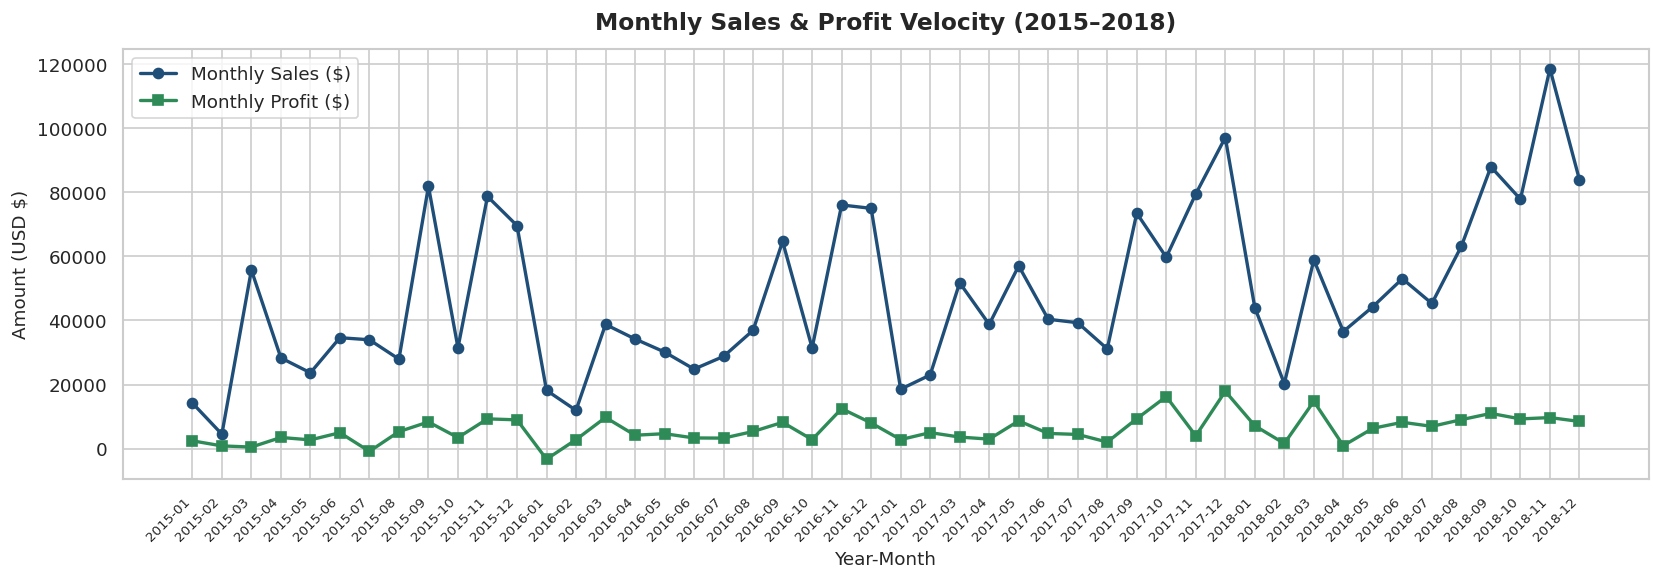

In [27]:
# --- Chart 1: Monthly Sales & Profit Velocity (2015–2018) ---
monthly_velocity = df.groupby("Year-Month", as_index=False).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_velocity["Year-Month"], monthly_velocity["Sales"], marker="o", linewidth=2, color="#1f4e78", label="Monthly Sales ($)")
ax.plot(monthly_velocity["Year-Month"], monthly_velocity["Profit"], marker="s", linewidth=2, color="#2e8b57", label="Monthly Profit ($)")
ax.set_title("Monthly Sales & Profit Velocity (2015–2018)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Year-Month", fontsize=11)
ax.set_ylabel("Amount (USD $)", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("01_monthly_sales_velocity.png", dpi=150)
plt.show()

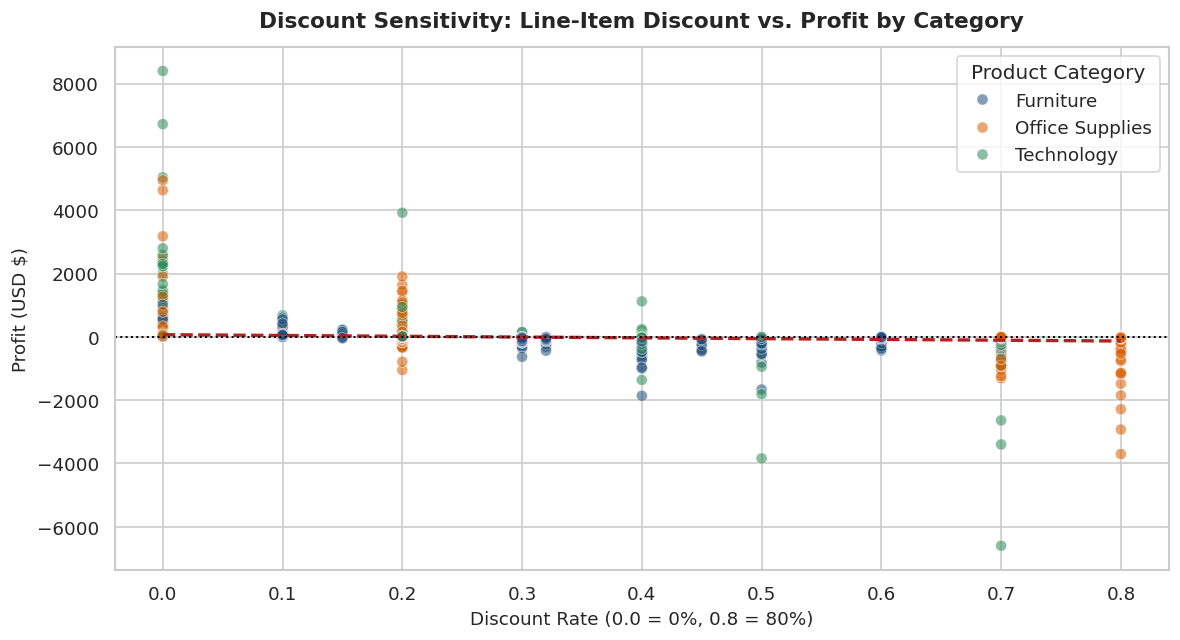

In [28]:
# --- Chart 2: Discount vs. Profit Scatter Plot with Regression Trend ---
corr_r = df["Discount"].corr(df["Profit"])  # Pearson correlation coefficient (-0.22)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(
    data=df, x="Discount", y="Profit", hue="Category",
    alpha=0.55, s=45, palette=["#1f4e78", "#d95f02", "#2e8b57"], ax=ax
)
sns.regplot(
    data=df, x="Discount", y="Profit", scatter=False,
    color="#b22222", line_kws={"linestyle": "--", "linewidth": 2, "label": f"Linear Trend (r = {corr_r:.2f})"}, ax=ax
)
ax.axhline(0, color="black", linestyle=":", linewidth=1.2)  # Break-even profit reference line
ax.set_title("Discount Sensitivity: Line-Item Discount vs. Profit by Category", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Discount Rate (0.0 = 0%, 0.8 = 80%)", fontsize=11)
ax.set_ylabel("Profit (USD $)", fontsize=11)
ax.legend(title="Product Category")
plt.tight_layout()
plt.savefig("02_discount_vs_profit.png", dpi=150)
plt.show()

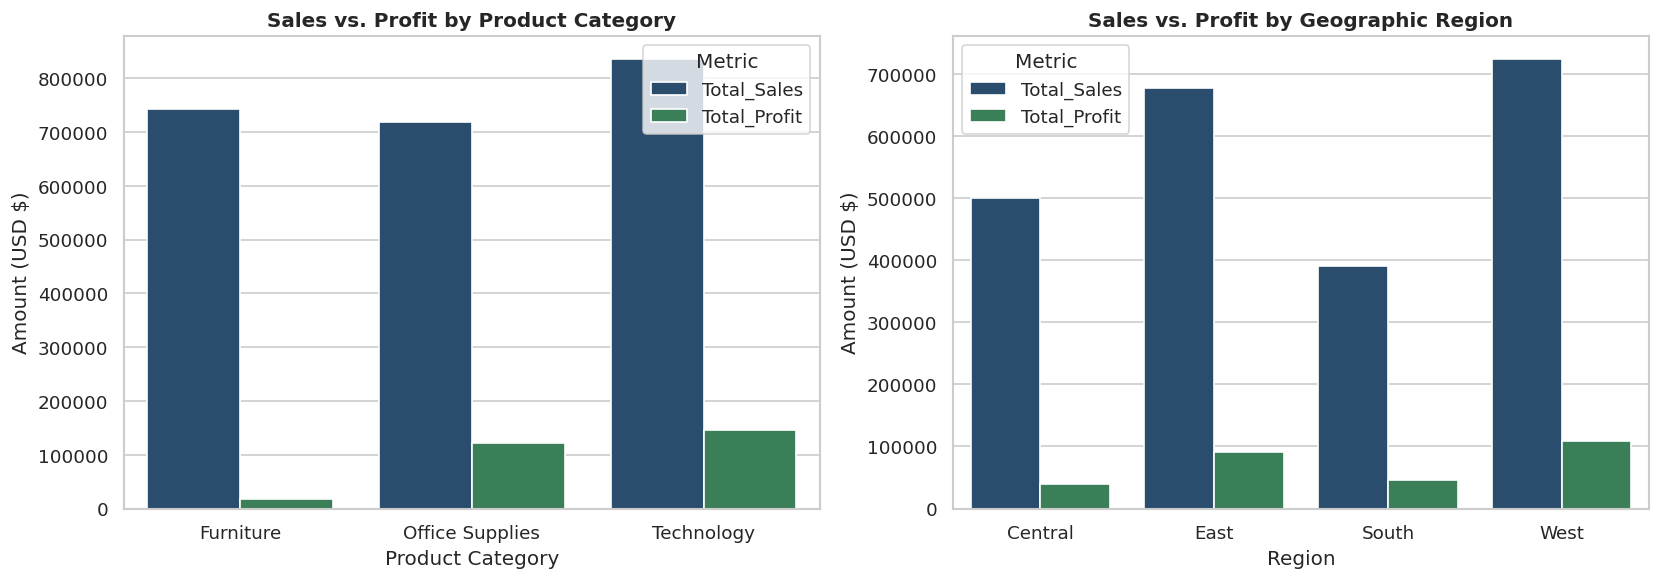

In [29]:
# --- Chart 3: Category & Regional Sales vs. Profit Comparison ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Product Category Sales vs. Profit
cat_plot = cat_summary.melt(id_vars="Category", value_vars=["Total_Sales", "Total_Profit"], var_name="Metric", value_name="USD")
sns.barplot(data=cat_plot, x="Category", y="USD", hue="Metric", palette=["#1f4e78", "#2e8b57"], ax=axes[0])
axes[0].set_title("Sales vs. Profit by Product Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Amount (USD $)")

# Subplot B: Geographic Region Sales vs. Profit
reg_plot = reg_summary.melt(id_vars="Region", value_vars=["Total_Sales", "Total_Profit"], var_name="Metric", value_name="USD")
sns.barplot(data=reg_plot, x="Region", y="USD", hue="Metric", palette=["#1f4e78", "#2e8b57"], ax=axes[1])
axes[1].set_title("Sales vs. Profit by Geographic Region", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Amount (USD $)")

plt.tight_layout()
plt.savefig("03_category_region_performance.png", dpi=150)
plt.show()

<h3> <font color="crimson">Executive Takeaways & Strategic Recommendations</h3>

## Executive Takeaways & Strategic Recommendations

1. **Aggressive Discounting Above 20% Erodes Unit Economics:**
   Discount rate exhibits a negative correlation with profit (`r = -0.22`). Line items sold at **0% discount** generate **\$320,988 in profit (29.51% profit margin)** with zero loss-making orders, whereas discounts in the **21%–40% tier** drop margins to **-15.30%** (90.22% of items unprofitable) and discounts **above 40%** collapse margins to **-77.40%** (-\$\$99,559 net loss across 933 line items). **Recommendation:** Enforce a 20% automated discount ceiling requiring director approval for deeper markdowns.

2. **Furniture Generates High Revenue with Near-Zero Net Margin:**
   While all three categories generate comparable top-line sales—**Technology (\$836.2K)**, **Furniture (\$742.0K)**, and **Office Supplies (\$719.0K)**—**Technology** produces **50.79% of total company profit (\$145.5K, 17.40% margin)**, whereas **Furniture** delivers only **6.44% of profit (\$18.5K, 2.49% margin)**. Losses are driven by **Tables (-\$17,725; -8.56% margin)** and **Bookcases (-\$3,473; -3.02% margin)** due to steep discounting (26.1% and 21.1% average discounts) and freight costs. **Recommendation:** Re-price Tables and Bookcases and introduce minimum order quantities.

3. **Late-Year Seasonality Concentrates Revenue in September–December:**
   Order volume surges sharply in the final four months of the year: **November (\$352.5K, 15.34% of annual sales)**, **December (\$325.3K, 14.16%)**, and **September (\$307.6K, 13.39%)** combine for **42.89% of total revenue**, compared to **February (\$59.8K, 2.60%)** and **January (\$94.9K, 4.13%)**. **Recommendation:** Front-load inventory procurement in August and launch targeted Q1 B2B restocking campaigns.

4. **Central Region Margin Compression Mirrors Discount Overuse:**
   **West** leads all regions in both revenue (**\$725.5K**) and profit margin (**14.94%**, \$108.4K profit) while maintaining the lowest average discount (**10.93%**). Conversely, **Central** records the lowest profit margin (**7.92%**, \$39.7K profit on \$501.2K sales—less total profit than the smaller **South** region's \$46.7K) driven by a **24.04% average discount rate**. **Recommendation:** Align Central regional promotional policies with West and East benchmarks.

5. **Consumer Leads Volume, While Corporate & Home Office Yield Higher Margins:**
   The **Consumer** segment accounts for **50.56% of total revenue (\$1.16M across 2,586 orders)** at an **11.55% profit margin**, whereas **Home Office (\$429.7K, 14.03% margin)** and **Corporate (\$706.1K, 13.03% margin)** deliver stronger profitability per sales dollar. **Recommendation:** Expand B2B account acquisition in Corporate and Home Office while tightening promotional margin controls in Consumer.